In [1]:
import pandas as pd
df=pd.read_csv("car data.csv")
print(df.shape)
df.head()


(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [3]:
#checking missing or null values
df.isnull().sum()


Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

In [ ]:
#checking duplicated values or rows
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()#remove duplicate rows
print("New shape:", df.shape)



Duplicates: 2
New shape: (299, 9)


In [6]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.566332,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [7]:
for col in ["Fuel_Type", "Selling_type", "Transmission"]:
    print(df[col].value_counts(), "\n")

Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64 

Selling_type
Dealer        193
Individual    106
Name: count, dtype: int64 

Transmission
Manual       260
Automatic     39
Name: count, dtype: int64 



In [9]:
#EDA 
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

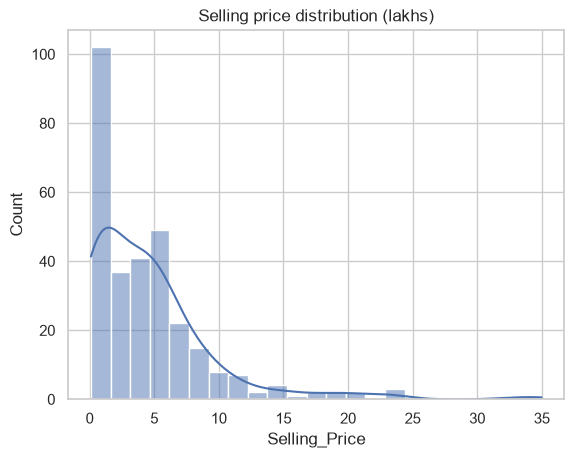

In [10]:
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Selling price distribution (lakhs)")
plt.show()

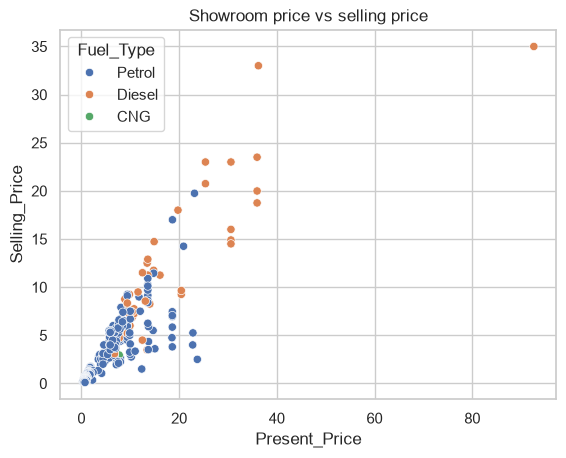

In [11]:
#Showroom price vs. selling price

sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Fuel_Type")
plt.title("Showroom price vs selling price")
plt.show()

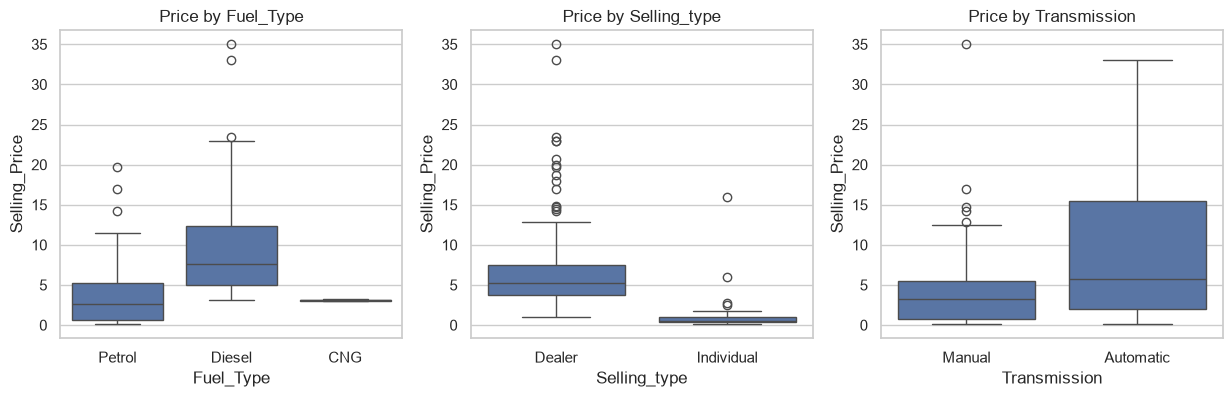

In [12]:
#Price by category
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["Fuel_Type", "Selling_type", "Transmission"]):
    sns.boxplot(data=df, x=col, y="Selling_Price", ax=a)
    a.set_title(f"Price by {col}")
plt.show()

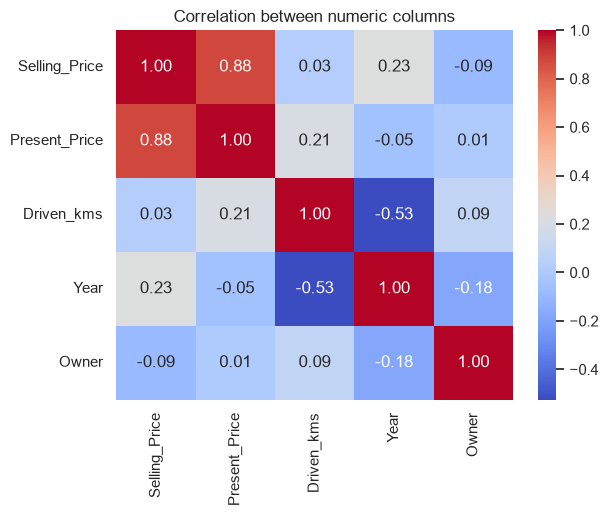

In [13]:
#Correlation heatmap
num_cols = ["Selling_Price", "Present_Price", "Driven_kms", "Year", "Owner"]
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between numeric columns")
plt.show()

In [14]:
#feature engineering, here we create new, better columns, convert text into numbers, and fix the skew

import numpy as np

df["Car_Age"] = 2026 - df["Year"]

df["Brand"] = df["Car_Name"].str.split().str[0].str.lower()
print(df["Brand"].nunique(), "different brands")

44 different brands


In [15]:
counts = df["Brand"].value_counts()
df["Brand"] = df["Brand"].where(df["Brand"].map(counts) >= 3, "other")
print(df["Brand"].value_counts())

Brand
city        26
bajaj       25
royal       17
corolla     17
honda       17
hero        15
verna       14
other       14
etios       11
fortuner    10
brio        10
i20          9
innova       9
ciaz         9
yamaha       8
tvs          8
grand        8
amaze        7
jazz         7
eon          6
alto         6
sx4          6
swift        5
ertiga       5
i10          5
dzire        4
wagon        4
ritz         4
ktm          4
activa       3
creta        3
xcent        3
Name: count, dtype: int64


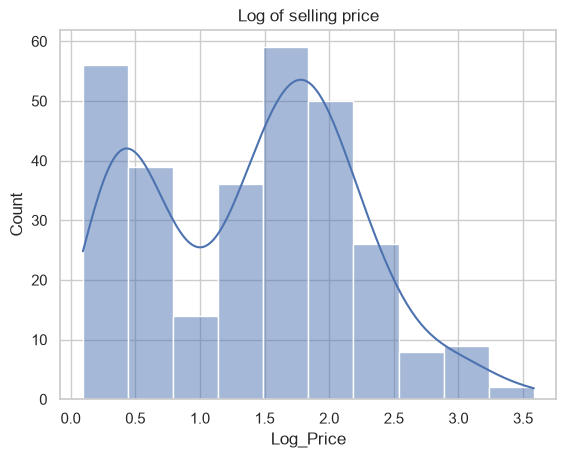

In [16]:
df["Log_Kms"] = np.log1p(df["Driven_kms"])
df["Log_Price"] = np.log1p(df["Selling_Price"])

sns.histplot(df["Log_Price"], kde=True)
plt.title("Log of selling price")
plt.show()

In [17]:
features = ["Present_Price", "Log_Kms", "Car_Age", "Owner",
            "Fuel_Type", "Selling_type", "Transmission", "Brand"]

X = pd.get_dummies(df[features], drop_first=True, dtype=int)
print(X.shape)
X.head()

(299, 39)


,Present_Price,Log_Kms,Car_Age,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual,Brand_alto,Brand_amaze,...,Brand_other,Brand_ritz,Brand_royal,Brand_swift,Brand_sx4,Brand_tvs,Brand_verna,Brand_wagon,Brand_xcent,Brand_yamaha
0,5.59,10.203629,12,0,0,1,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
1,9.54,10.668979,13,0,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
2,9.85,8.839422,9,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4.15,8.556606,15,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,6.87,10.656106,12,0,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0


In [18]:
y = df["Log_Price"]

In [19]:
#splitting the data into training and testing sets, and why the model must never see the test data while it learns
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training:", X_train.shape)
print("Testing: ", X_test.shape)

Training: (239, 39)
Testing:  (60, 39)


In [23]:
#training 4 different models, comparing them, and understanding how R², MAE, and RMSE measure how good a model is.
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Lasso Regression": Lasso(alpha=0.001, max_iter=10000),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=3, random_state=42),
}

In [24]:
#train and split every model 
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    # 1. Cross-validation on the training data only
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean()

    # 2. Train on all training data
    model.fit(X_train, y_train)

    # 3. Predict on the locked test set, and convert log price back to real price
    pred = np.expm1(model.predict(X_test))
    actual = np.expm1(y_test)

    results.append({
        "Model": name,
        "CV R2": round(cv_r2, 3),
        "Test R2": round(r2_score(actual, pred), 3),
        "MAE": round(mean_absolute_error(actual, pred), 3),
        "RMSE": round(np.sqrt(mean_squared_error(actual, pred)), 3),
    })

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False)
results_df

,Model,CV R2,Test R2,MAE,RMSE
1,Lasso Regression,0.855,0.930,0.802,1.342
0,Linear Regression,0.877,0.929,0.765,1.353
3,Gradient Boosting,0.972,0.815,0.964,2.186
2,Random Forest,0.971,0.636,1.279,3.062


In [25]:
check = X_test[["Present_Price", "Car_Age"]].copy()
check["Actual"] = np.expm1(y_test).round(2)
check["Linear_pred"] = np.expm1(models["Linear Regression"].predict(X_test)).round(2)
check["RF_pred"] = np.expm1(models["Random Forest"].predict(X_test)).round(2)
check["RF_error"] = (check["Actual"] - check["RF_pred"]).abs().round(2)

print("Most expensive car in training:", np.expm1(y_train).max().round(2))
check.sort_values("RF_error", ascending=False).head()

Most expensive car in training: 35.0


,Present_Price,Car_Age,Actual,Linear_pred,RF_pred,RF_error
85,23.73,20,2.50,2.18,16.90,14.40
64,36.23,9,33.00,28.89,21.63,11.37
94,22.78,18,4.00,6.21,13.81,9.81
78,22.83,16,5.25,7.36,14.53,9.28
83,13.46,11,12.50,10.87,9.84,2.66


In [26]:
#now we will see what linear regression learned 
lin = models["Linear Regression"]

coef = pd.Series(lin.coef_, index=X.columns)
effect = ((np.exp(coef) - 1) * 100).round(1)   # convert to % change in price

main = ["Present_Price", "Car_Age", "Log_Kms", "Owner",
        "Fuel_Type_Diesel", "Fuel_Type_Petrol",
        "Selling_type_Individual", "Transmission_Manual"]
effect[main]

Present_Price               3.1
Car_Age                    -7.0
Log_Kms                    -1.5
Owner                       1.2
Fuel_Type_Diesel           21.7
Fuel_Type_Petrol           13.7
Selling_type_Individual   -25.4
Transmission_Manual        -7.3
dtype: float64

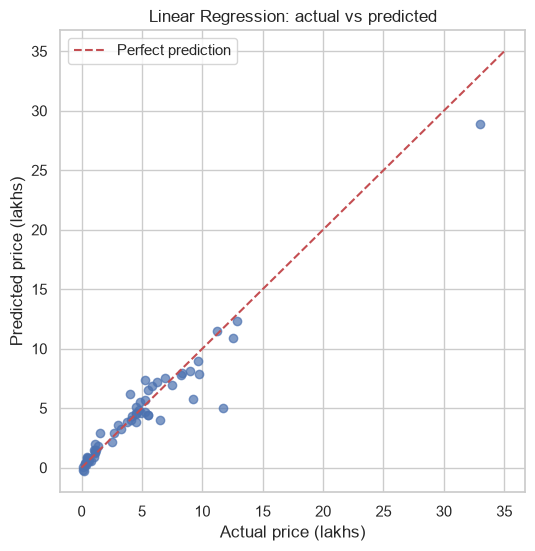

In [27]:
#actual vs predicted chart
pred = np.expm1(lin.predict(X_test))
actual = np.expm1(y_test)

plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.7)
plt.plot([0, 35], [0, 35], "r--", label="Perfect prediction")
plt.xlabel("Actual price (lakhs)")
plt.ylabel("Predicted price (lakhs)")
plt.title("Linear Regression: actual vs predicted")
plt.legend()
plt.show()

In [28]:
#pridcting own car price
def predict_price(present_price, kms, year, owner, fuel, seller, transmission, brand="other"):
    row = pd.DataFrame(0, index=[0], columns=X.columns)   # one empty row, same columns as X
    row["Present_Price"] = present_price
    row["Log_Kms"] = np.log1p(kms)
    row["Car_Age"] = 2026 - year
    row["Owner"] = owner
    for col in [f"Fuel_Type_{fuel}", f"Selling_type_{seller}",
                f"Transmission_{transmission}", f"Brand_{brand.lower()}"]:
        if col in row.columns:
            row[col] = 1
    return np.expm1(lin.predict(row))[0]

print(predict_price(9.85, 6900, 2017, 0, "Petrol", "Dealer", "Manual", "city"))

8.304176168825846
